# Salary Patterns Across Data Roles and Skills

This notebook explores annual salary distributions for major data roles in the United States and then focuses on how individual skills relate to Data Analyst pay. Only postings with a reported average yearly salary are included in the salary comparisons.

## Analysis approach

1. Prepare the job-postings dataset and retain U.S. records with annual salary data.
2. Compare salary distributions for the six most frequently posted data roles.
3. Isolate Data Analyst postings and expand their listed skills.
4. Calculate skill-level posting counts and median salaries.
5. Contrast the highest-paying skills with the most commonly requested skills.

## Load and prepare the data

Import the analysis libraries, load the job-postings dataset, and convert the posting date and skills fields into usable data types.

In [2]:
# Importing Libraries
import ast

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from datasets import load_dataset

# Loading Data
dataset = load_dataset("lukebarousse/data_jobs")
df = dataset["train"].to_pandas()

# Data Cleanup
df["job_posted_date"] = pd.to_datetime(df["job_posted_date"])
df["job_skills"] = df["job_skills"].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

## Create the U.S. salary sample

Limit the analysis to United States postings and remove records without `salary_year_avg`. The resulting sample supports comparable annual-salary statistics.

In [ ]:
df_US = df[df["job_country"] == "United States"].dropna(subset="salary_year_avg")

# Set Theme
sns.set_theme(style="ticks", font_scale=1.2)

## Select and order the leading data roles

Identify the six job-title categories with the most salary-reported postings, retain those roles, and order them by median annual salary for the comparison chart.

In [5]:
job_titles = df_US["job_title_short"].value_counts().index[:6].tolist()

job_titles

['Data Scientist',
 'Data Analyst',
 'Data Engineer',
 'Senior Data Scientist',
 'Senior Data Engineer',
 'Senior Data Analyst']

In [7]:
df_US_top_6 = df_US[df_US["job_title_short"].isin(job_titles)]

In [13]:
job_order = df_US_top_6.groupby("job_title_short")["salary_year_avg"].median().sort_values(ascending=False).index

## Compare role-level salary distributions

Use a box plot to show each role's salary spread, median, and potential outliers. The common horizontal scale makes differences across roles easier to assess.

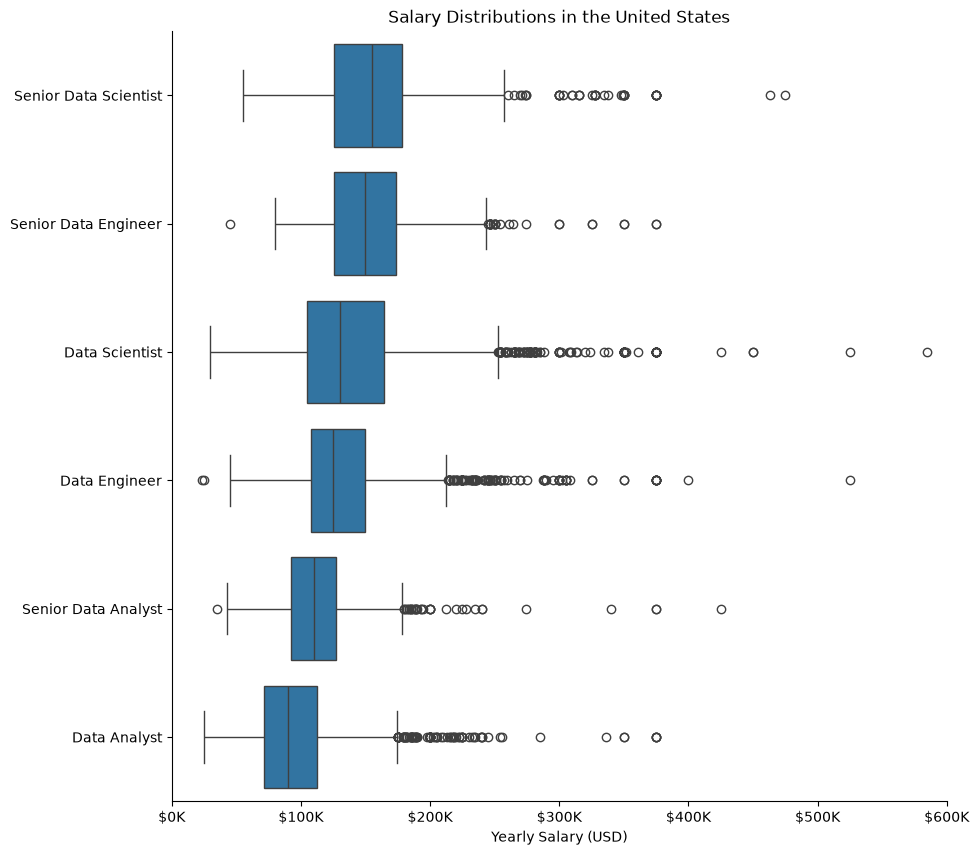

In [14]:
fig, ax = plt.subplots(figsize=(10, 10))

sns.boxplot(data=df_US_top_6, x="salary_year_avg", y="job_title_short", ax=ax, order=job_order)
sns.despine()

plt.title("Salary Distributions in the United States")
plt.xlabel("Yearly Salary (USD)")
plt.ylabel("")
plt.xlim(0, 600_000)

ticks_x = plt.FuncFormatter(lambda y, pos: f"${int(y / 1000)}K")
plt.gca().xaxis.set_major_formatter(ticks_x)

plt.show()

## Focus on Data Analyst skill pay

Narrow the dataset to U.S. Data Analyst postings and keep only records with a reported average yearly salary.

In [ ]:
# Only get data analyst jobs
df_DA_US = df[
	(df["job_title_short"] == "Data Analyst") & (df["job_country"] == "United States")
].copy()

# Drop NaN values
df_DA_US = df_DA_US.dropna(subset="salary_year_avg")

## Expand postings into individual skills

Explode the skills list so each posting-skill combination occupies its own row. This allows salary observations to be grouped by skill.

In [18]:
df_DA_US = df_DA_US.explode("job_skills")

df_DA_US[["salary_year_avg", "job_skills"]].sample(5)

,salary_year_avg,job_skills
183368,75368.5,outlook
157652,115000.0,sas
162898,77500.0,azure
205289,70000.0,nosql
687030,84500.0,tableau


## Identify the highest-paying skills

Calculate the number of salary observations and median annual salary for each skill, then retain the ten skills with the highest medians.

In [22]:
df_DA_top_pay = df_DA_US.groupby("job_skills")["salary_year_avg"].agg(["count", "median"]).sort_values(by="median", ascending=False)
df_DA_top_pay = df_DA_top_pay.head(10)

df_DA_top_pay

,count,median
job_skills,,
dplyr,2,196250.0
bitbucket,3,189000.0
gitlab,3,186000.0
solidity,1,179000.0
hugging face,1,175000.0
couchbase,1,160515.0
ansible,1,159640.0
mxnet,2,149000.0
cassandra,6,148250.0


## Evaluate the most frequently listed skills

Select the ten skills with the most salary observations, then order that subset by median salary. This separates broad market demand from pay level.

In [24]:
df_DA_skills = df_DA_US.groupby("job_skills")["salary_year_avg"].agg(["count", "median"]).sort_values(by="count", ascending=False)
df_DA_skills = df_DA_skills.head(10).sort_values(by="median", ascending=False)

df_DA_skills

,count,median
job_skills,,
python,1431,97500.00
tableau,1364,92875.00
r,893,92500.00
sql server,286,92500.00
sql,2508,91000.00
sas,926,90000.00
power bi,838,90000.00
powerpoint,462,85000.00
excel,1808,84392.00


## Compare high pay with high demand

Display the median salaries of the highest-paying skills alongside those of the most frequently requested skills. The two panels answer different questions and should not be interpreted as the same ranking.

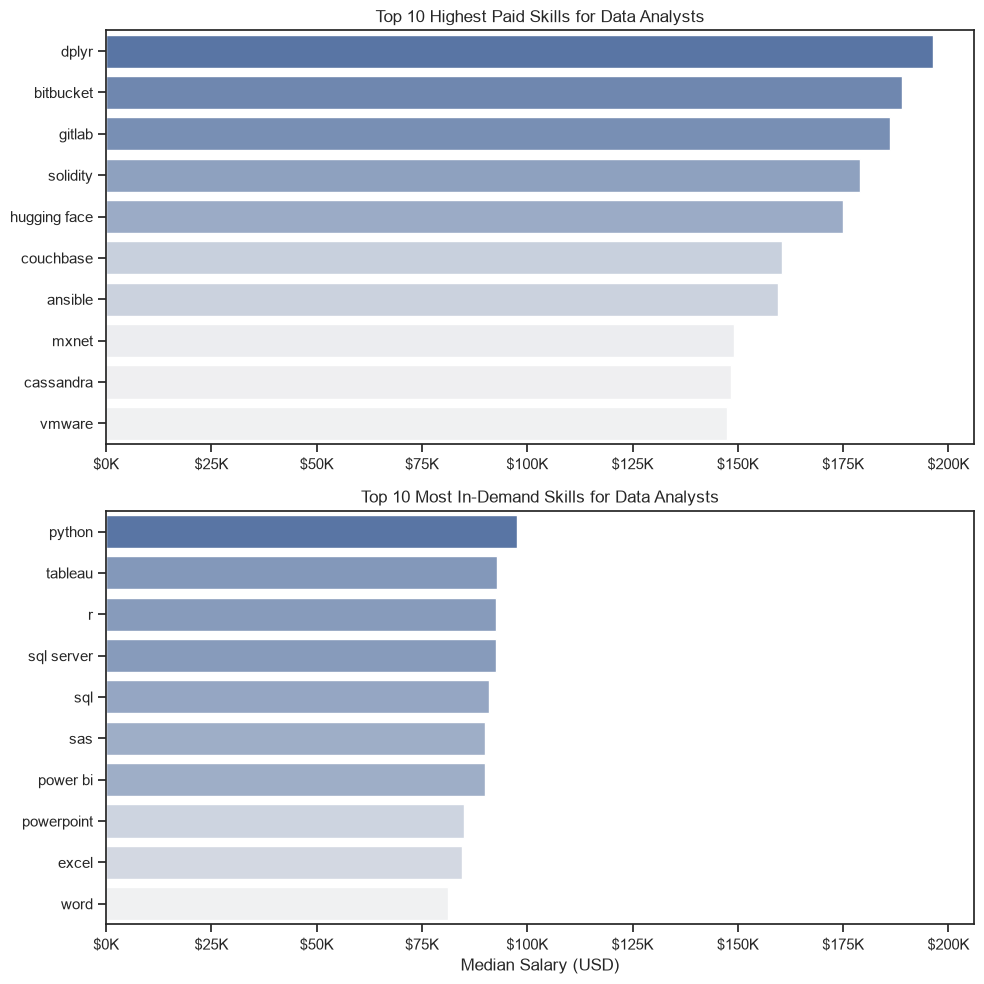

In [ ]:
# Create plots
fig, ax = plt.subplots(2, 1, figsize=(10, 10))

# Top 10 Highest Paid Skills
sns.barplot(
	x=df_DA_top_pay["median"],
	y=df_DA_top_pay.index,
	ax=ax[0],
	hue=df_DA_top_pay["median"],
	palette="light:b",
)
ax[0].legend().remove()
ax[0].set_title("Top 10 Highest Paid Skills for Data Analysts")
ax[0].set_xlabel("")
ax[0].set_ylabel("")
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${int(x / 1000)}K"))

# Top 10 Most In-Demand Skills
sns.barplot(
	x=df_DA_skills["median"],
	y=df_DA_skills.index,
	ax=ax[1],
	hue=df_DA_skills["median"],
	palette="light:b",
)
ax[1].legend().remove()
ax[1].set_title("Top 10 Most In-Demand Skills for Data Analysts")
ax[1].set_xlabel("Median Salary (USD)")
ax[1].set_ylabel("")
ax[1].set_xlim(ax[0].get_xlim())
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${int(x / 1000)}K"))

plt.tight_layout()
plt.show()